# 09 · Route profiles and exploratory clustering

**Question:** Which Manhattan routes have similar observed demand and scheduled-service
patterns, and how sensitive are those groups to observation weeks and modelling choices?

The clustering unit is **one route**, combining directions because the boarding source does
not identify direction. Demand is joined to previously validated historical schedules.
Groups are descriptive: no occupancy, efficiency or service-change labels are available.

The fixed window is 6 July–27 September 2026: twelve complete calendar weeks inside the
hourly pilot. All routes use the same complete eligible dates. Known zero service and
genuine zero boardings remain observations. Invalid dates are withheld for the whole cohort.

This is retrospective exploration of a small network. Silhouette and stability are diagnostics,
not classification accuracy or proof of naturally distinct types. Earlier forecasts are preserved.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import importlib.metadata
import json
import pickle
import sys
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display, Markdown
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from threadpoolctl import threadpool_limits

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "PROJECT.md").exists())
sys.path.insert(0, str(ROOT))
from scripts.route_profiles import (
    FEATURES, WEIGHTS, common_profile_members, build_route_profiles,
    choose_cluster_count, align_labels,
)
DATA = ROOT / "data/processed/new_york"
OUT = DATA / "route_clustering"
REPORT = ROOT / "reports/route_clustering"
FIGURES = REPORT / "figures"
for folder in [OUT, REPORT, FIGURES]:
    folder.mkdir(parents=True, exist_ok=True)

def sha256(path):
    with Path(path).open("rb") as handle:
        return hashlib.file_digest(handle, "sha256").hexdigest()

protected_paths = sorted(
    [p for p in DATA.rglob("*") if p.is_file() and OUT not in p.parents]
    + list((ROOT / "notebooks/new_york").glob("0[1-8]_*.ipynb"))
)
protected_before = {p.relative_to(ROOT).as_posix(): sha256(p) for p in protected_paths}
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 10, "axes.titlesize": 12, "figure.constrained_layout.use": True})
pd.set_option("display.max_columns", 12)
print("Runtime:", platform.python_version(), "| scikit-learn:", importlib.metadata.version("scikit-learn"))
print("Earlier products and notebooks protected:", len(protected_before))

Runtime: 3.11.9 | scikit-learn: 1.8.0
Earlier products and notebooks protected: 144


## 1. Fix the protocol and verify inputs

Three features describe demand: log weekday boardings, equal-day-type weekend retention,
and the weekday share in 07:00–10:00 plus 16:00–19:00. Two describe scheduled service:
log weekday bus-hours and equal-day-type weekend service retention.

Median/IQR scaling is followed by multipliers 1/√3 for demand and 1/√2 for service.
Both blocks receive equal nominal total squared weight. This explicit distance choice
is not learned feature importance or a claim that inputs are independent.

Compare KMeans k=2–5, 30 initializations and a fixed seed. Prefer the smallest k within
0.02 of the best silhouette among partitions with at least four routes per group.
If none passes, retain only a labelled descriptive partition and report the failed screen.
The size and tolerance rules are pragmatic safeguards for this case, not universal standards.

Use DBSCAN as a density sensitivity analysis. Freeze k before 80 whole-week bootstrap
refits, representation sensitivity and a first-six-weeks versus last-six-weeks comparison.
No forecast outcome is used to choose groups.

In [2]:
PROTOCOL = {
    "window_start": "2026-07-06", "window_end": "2026-09-27",
    "minimum_days": {"Weekday": 40, "Saturday": 8, "Sunday": 8},
    "features": FEATURES, "weights": WEIGHTS.tolist(),
    "candidate_k": [2, 3, 4, 5], "minimum_cluster_size": 4,
    "silhouette_tolerance": 0.02, "seed": 42, "n_init": 30,
    "bootstrap_repetitions": 80, "minimum_valid_bootstraps": 60,
    "bootstrap_minimum_days": {"Weekday": 20, "Saturday": 5, "Sunday": 5},
    "assignment_review_below": 0.8, "margin_review_below": 0.1,
    "dbscan_eps": [0.5, 0.8, 1.2, 1.6, 2.0], "dbscan_min_samples": 4,
}
input_names = ["matched_daily_features", "matched_hourly_features", "route_structure",
               "route_crosswalk", "map_shapes", "map_route_shapes"]
feature_manifest = json.loads((DATA / "feature_manifest.json").read_text())
assert feature_manifest["inputs"]["cleaning_manifest_sha256"] == sha256(DATA / "cleaning_manifest.json")
cleaning_manifest = json.loads((DATA / "cleaning_manifest.json").read_text())
product_receipts = {**cleaning_manifest["products"], **feature_manifest["products"]}
input_register = []
for name in input_names:
    path = DATA / f"{name}.csv"
    observed_hash = sha256(path)
    assert observed_hash == product_receipts[name]["sha256"], name
    input_register.append({"product": name, "sha256": observed_hash})
daily = pd.read_csv(DATA / "matched_daily_features.csv", low_memory=False,
                    dtype={"bus_route": "string"}, parse_dates=["payment_date"])
hourly = pd.read_csv(DATA / "matched_hourly_features.csv", dtype={"bus_route": "string"},
                     parse_dates=["payment_date", "local_hour"])
structure = pd.read_csv(DATA / "route_structure.csv", dtype={"bus_route": "string"})
crosswalk = pd.read_csv(DATA / "route_crosswalk.csv", dtype={"bus_route": "string"})
cohort = sorted(structure.bus_route.tolist())
assert len(cohort) == 41 and not structure.bus_route.duplicated().any()
assert structure.snapshot_id.nunique() == 1
print("Window:", PROTOCOL["window_start"], "to", PROTOCOL["window_end"])
print("Routes:", len(cohort), "| Features:", len(FEATURES), "| Candidate k:", PROTOCOL["candidate_k"])
display(pd.DataFrame(input_register))

Window: 2026-07-06 to 2026-09-27
Routes: 41 | Features: 5 | Candidate k: [2, 3, 4, 5]


,product,sha256
0,matched_daily_features,eb335add5fe299ed2984bec85aec5d9c2253fdf8b5d8d4...
1,matched_hourly_features,ad63bee39c4efb9c0b1b772b4aa7a3245e4fb9e0fe52ae...
2,route_structure,42f37ffd890f52110f42dfe8751e8b48ad095174d538f0...
3,route_crosswalk,ae03410e80552e6d2fded6561e13201de9f280dfccfdc3...
4,map_shapes,ca8fe1b6b2f526a4b70e777de0c76a78d37db92de611c5...
5,map_route_shapes,f3cc74fb7d5934d39d60baf0e97a6417094c76195032b3...


## 2. Use exactly the same observation dates

An included date requires all routes, known nonnegative scheduled totals, eligible calendar
context, valid demand, 24 unique hourly observations and agreement between hourly and daily
boardings. Common dates prevent comparisons of profiles built from different periods.
The coverage table shows the individual-route data sacrificed by this restriction.
Known zero service is retained, with a separate context flag.

Included dates: 78 / 84
Excluded dates: 6 | Route/date observations: 3198


,dates,route_dates
day_type,,
Saturday,11,451
Sunday,10,410
Weekday,57,2337


,payment_date,expected_routes,observed_routes,eligible_routes,unavailable_demand_routes,unavailable_schedule_routes,incomplete_hourly_routes,unreconciled_routes,included
41,2026-08-16,41,41,0,41,0,41,0,False
59,2026-09-03,41,41,0,0,41,0,0,False
60,2026-09-04,41,41,0,0,41,0,0,False
61,2026-09-05,41,41,0,0,41,0,0,False
62,2026-09-06,41,41,0,0,41,0,0,False
63,2026-09-07,41,41,40,0,1,0,0,False


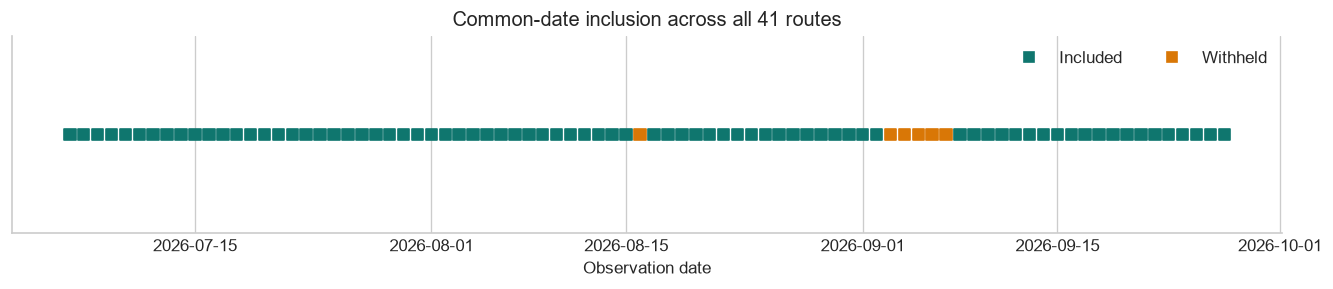

In [3]:
members, coverage = common_profile_members(
    daily, hourly, cohort, PROTOCOL["window_start"], PROTOCOL["window_end"])
assert len(members) == len(cohort) * coverage.included.sum()
support = members.groupby("day_type").agg(dates=("payment_date", "nunique"),
                                         route_dates=("bus_route", "size"))
print("Included dates:", int(coverage.included.sum()), "/", len(coverage))
print("Excluded dates:", int((~coverage.included).sum()), "| Route/date observations:", len(members))
display(support)
display(coverage.loc[~coverage.included])
fig, ax = plt.subplots(figsize=(11, 2.3))
ax.scatter(coverage.payment_date, np.ones(len(coverage)),
           c=np.where(coverage.included, "#0f766e", "#d97706"), marker="s", s=48)
ax.set(yticks=[], ylim=(0.5, 1.5), title="Common-date inclusion across all 41 routes",
       xlabel="Observation date")
ax.legend(handles=[Line2D([], [], color="#0f766e", marker="s", linestyle="", label="Included"),
                   Line2D([], [], color="#d97706", marker="s", linestyle="", label="Withheld")],
          loc="upper right", ncols=2)
fig.savefig(FIGURES / "common_date_coverage.png", bbox_inches="tight")
plt.show()

## 3. Build interpretable profiles

Weekend retention is (mean Saturday + mean Sunday) / (2 × mean weekday). Giving both
weekend day types equal weight prevents missing Sundays from changing that definition.
Peak share divides summed peak-hour boardings by summed weekday boardings.

Length, stops and duration remain September-snapshot context, outside the modelling inputs.
Boarding/service ratios are contextual too, avoiding duplicate representations of their components.

In [4]:
profiles = build_route_profiles(members, PROTOCOL["minimum_days"])
identity = crosswalk.loc[crosswalk.snapshot_id.eq(structure.snapshot_id.iloc[0]),
                         ["bus_route", "route_long_name"]]
assert not identity.bus_route.duplicated().any()
profiles = profiles.merge(identity, on="bus_route", validate="one_to_one").merge(
    structure, on="bus_route", validate="one_to_one").sort_values("bus_route").reset_index(drop=True)
positive_without_service = members.loc[
    members.scheduled_service_hours.eq(0) & members.analysis_boardings.gt(0)
].groupby("bus_route").size()
profiles["positive_boardings_zero_service_dates"] = (
    profiles.bus_route.map(positive_without_service).fillna(0).astype(int))
assert profiles.bus_route.tolist() == cohort
display(profiles[["bus_route", "mean_weekday_boardings", "weekend_boarding_ratio",
                  "weekday_peak_share", "mean_weekday_service_hours",
                  "weekend_service_ratio"]].head(12).round(3))
display(profiles[FEATURES].describe().round(3))
display(profiles.loc[profiles.zero_service_dates.gt(0), [
    "bus_route", "zero_service_dates", "positive_boardings_zero_service_dates"]])
print("Complete profiles:", profiles.shape, "| Missing modelling inputs:", profiles[FEATURES].isna().sum().sum())

,bus_route,mean_weekday_boardings,weekend_boarding_ratio,weekday_peak_share,mean_weekday_service_hours,weekend_service_ratio
0,M1,7732.456,0.637,0.482,293.994,0.552
1,M10,2804.807,1.009,0.441,135.062,0.893
2,M101,11838.228,0.632,0.425,509.038,0.611
3,M102,6991.491,0.681,0.435,273.489,0.727
4,M103,6584.439,0.752,0.409,242.171,0.743
5,M104,4944.789,1.246,0.397,175.302,1.464
6,M106,1352.018,0.299,0.576,36.150,0.404
7,M11,8224.719,0.693,0.438,225.613,0.642
8,M116,4158.596,0.536,0.477,109.055,0.699
9,M12,1136.825,0.944,0.470,33.150,0.826


,log_weekday_boardings,weekend_boarding_ratio,weekday_peak_share,log_weekday_service_hours,weekend_service_ratio
count,41.000,41.000,41.000,41.000,41.000
mean,8.376,0.688,0.474,4.856,0.684
std,0.952,0.408,0.063,0.744,0.216
min,5.343,0.001,0.393,3.531,0.000
25%,7.939,0.520,0.435,4.399,0.574
50%,8.579,0.598,0.472,4.913,0.648
75%,8.997,0.752,0.493,5.484,0.764
max,10.034,2.751,0.769,6.234,1.464


,bus_route,zero_service_dates,positive_boardings_zero_service_dates
40,M98,21,4


Complete profiles: (41, 32) | Missing modelling inputs: 0


## 4. Inspect the distance representation

Correlated inputs can give one underlying characteristic extra influence. Inspect their
correlations and test alternative feature choices later. Scaling is fitted on this retrospective
profile population; it is not a supervised train/test transformation or a future classifier.

,feature,meaning,block,distance_multiplier
0,log_weekday_boardings,log(1 + mean weekday boardings),Demand,0.577350
1,weekend_boarding_ratio,Equal-weight weekend / weekday boardings,Demand,0.577350
2,weekday_peak_share,Weekday peak-hour / all-hour boardings,Demand,0.577350
3,log_weekday_service_hours,log(1 + mean weekday bus-hours),Scheduled service,0.707107
4,weekend_service_ratio,Equal-weight weekend / weekday bus-hours,Scheduled service,0.707107


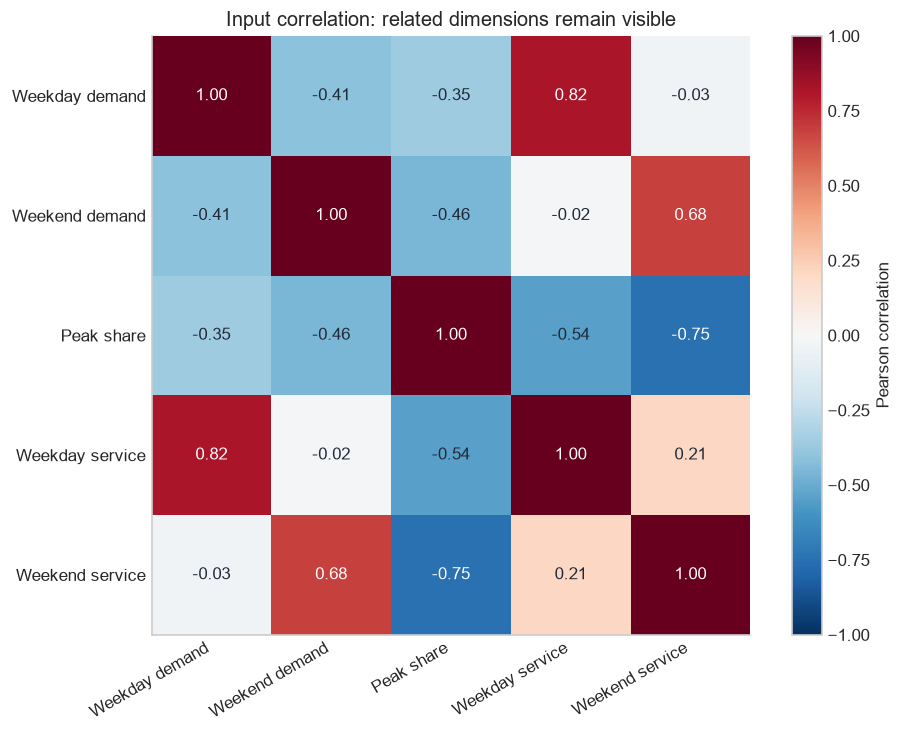

,log_weekday_boardings,weekend_boarding_ratio,weekday_peak_share,log_weekday_service_hours,weekend_service_ratio
bus_route,,,,,
M1,0.204,0.095,0.106,0.504,-0.357
M10,-0.349,1.022,-0.303,0.000,0.910
M101,0.437,0.083,-0.465,0.861,-0.138
M102,0.149,0.206,-0.365,0.457,0.295
M103,0.117,0.383,-0.622,0.378,0.353
M104,-0.040,1.612,-0.736,0.169,3.034
M106,-0.747,-0.745,1.027,-0.846,-0.909
M11,0.238,0.236,-0.335,0.332,-0.022


In [5]:
feature_definitions = pd.DataFrame({
    "feature": FEATURES,
    "meaning": ["log(1 + mean weekday boardings)", "Equal-weight weekend / weekday boardings",
                "Weekday peak-hour / all-hour boardings", "log(1 + mean weekday bus-hours)",
                "Equal-weight weekend / weekday bus-hours"],
    "block": ["Demand"] * 3 + ["Scheduled service"] * 2,
    "distance_multiplier": WEIGHTS,
})
display(feature_definitions)
correlations = profiles[FEATURES].corr()
fig, ax = plt.subplots(figsize=(8.2, 6))
image = ax.imshow(correlations, vmin=-1, vmax=1, cmap="RdBu_r")
ax.grid(False)
short_labels = ["Weekday demand", "Weekend demand", "Peak share", "Weekday service", "Weekend service"]
ax.set(xticks=range(5), yticks=range(5), xticklabels=short_labels, yticklabels=short_labels,
       title="Input correlation: related dimensions remain visible")
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
for i in range(5):
    for j in range(5):
        ax.text(j, i, f"{correlations.iloc[i, j]:.2f}", ha="center", va="center",
                color="white" if abs(correlations.iloc[i, j]) > .65 else "#1f2937")
fig.colorbar(image, ax=ax, label="Pearson correlation")
fig.savefig(FIGURES / "feature_correlations.png", bbox_inches="tight")
plt.show()

def fit_partition(frame, k, columns=FEATURES, scaler_kind="robust", weighted=True, seed=42):
    scaler = RobustScaler() if scaler_kind == "robust" else StandardScaler()
    multipliers = np.array([WEIGHTS[FEATURES.index(c)] for c in columns]) if weighted else np.ones(len(columns))
    scaled = scaler.fit_transform(frame[columns]) * multipliers
    with threadpool_limits(limits=1):
        model = KMeans(n_clusters=k, n_init=PROTOCOL["n_init"], random_state=seed)
        labels = model.fit_predict(scaled)
    return scaler, scaled, model, labels

scaler, scaled, _, _ = fit_partition(profiles, 2)
display(pd.DataFrame(scaled, columns=FEATURES, index=profiles.bus_route).head(8).round(3))

## 5. Compare small KMeans partitions

Silhouette compares within-group distance with the nearest other group. Higher separation
under this distance does not mean better transport outcomes. The size screen and near-tie
preference prevent a singleton or an unnecessary extra group from determining the display.

,k,silhouette,inertia,min_cluster_size,max_cluster_size,group_sizes,selected
0,2,0.5011,66.2312,6,35,"6,35",True
1,3,0.3119,46.6973,1,24,"1,16,24",False
2,4,0.4036,31.2211,1,28,"1,6,6,28",False
3,5,0.3396,20.0621,1,20,"1,1,5,14,20",False


Display partition: 2 groups | passes_descriptive_size_screen


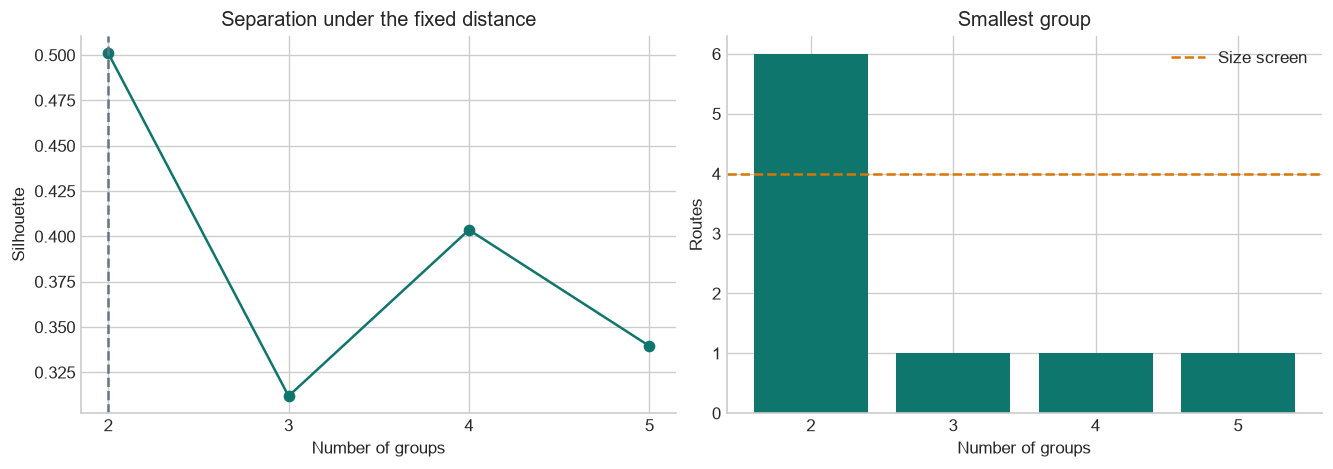

In [6]:
candidate_rows, partitions = [], {}
for k in PROTOCOL["candidate_k"]:
    fitted_scaler, x, fitted_model, labels = fit_partition(profiles, k)
    sizes = pd.Series(labels).value_counts()
    candidate_rows.append({"k": k, "silhouette": silhouette_score(x, labels),
                           "inertia": fitted_model.inertia_, "min_cluster_size": int(sizes.min()),
                           "max_cluster_size": int(sizes.max()),
                           "group_sizes": ",".join(map(str, sorted(sizes.tolist())))})
    partitions[k] = (fitted_scaler, x, fitted_model, labels)
candidates = pd.DataFrame(candidate_rows)
try:
    selected_k = choose_cluster_count(candidates, PROTOCOL["minimum_cluster_size"],
                                      PROTOCOL["silhouette_tolerance"])
    selection_status = "passes_descriptive_size_screen"
except ValueError:
    selected_k = int(candidates.sort_values(["silhouette", "k"], ascending=[False, True]).iloc[0].k)
    selection_status = "no_partition_passes_size_screen_descriptive_only"
scaler, scaled, model, labels = partitions[selected_k]
candidates["selected"] = candidates.k.eq(selected_k)
display(candidates.round(4))
print("Display partition:", selected_k, "groups |", selection_status)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(candidates.k, candidates.silhouette, marker="o", color="#0f766e")
axes[0].axvline(selected_k, linestyle="--", color="#64748b")
axes[0].set(title="Separation under the fixed distance", xlabel="Number of groups", ylabel="Silhouette",
            xticks=PROTOCOL["candidate_k"])
axes[1].bar(candidates.k, candidates.min_cluster_size, color="#0f766e")
axes[1].axhline(PROTOCOL["minimum_cluster_size"], linestyle="--", color="#d97706", label="Size screen")
axes[1].set(title="Smallest group", xlabel="Number of groups", ylabel="Routes",
            xticks=PROTOCOL["candidate_k"])
axes[1].legend()
fig.savefig(FIGURES / "candidate_partitions.png", bbox_inches="tight")
plt.show()

## 6. Check a density-based alternative

DBSCAN can leave routes unassigned as noise. That means no sufficiently dense neighbourhood
under the parameters, not a defective route. Its silhouette excludes noise and uses a different
population from KMeans. Do not rank these algorithms directly by those numbers.

In [7]:
dbscan_rows, dbscan_assignments = [], []
for eps in PROTOCOL["dbscan_eps"]:
    density_labels = DBSCAN(eps=eps, min_samples=PROTOCOL["dbscan_min_samples"]).fit_predict(scaled)
    assigned = density_labels >= 0
    groups = len(set(density_labels[assigned]))
    score = (silhouette_score(scaled[assigned], density_labels[assigned])
             if 1 < groups < int(assigned.sum()) else np.nan)
    dbscan_rows.append({"eps": eps, "min_samples": PROTOCOL["dbscan_min_samples"],
                       "groups_excluding_noise": groups, "assigned_routes": int(assigned.sum()),
                       "noise_routes": int((~assigned).sum()), "assigned_only_silhouette": score})
    dbscan_assignments.extend({"eps": eps, "bus_route": route, "density_group": int(label)}
                              for route, label in zip(cohort, density_labels))
dbscan_scores = pd.DataFrame(dbscan_rows)
dbscan_membership = pd.DataFrame(dbscan_assignments)
display(dbscan_scores.round(4))
print("Density analysis is a sensitivity view; it does not replace the fixed KMeans display partition.")

,eps,min_samples,groups_excluding_noise,assigned_routes,noise_routes,assigned_only_silhouette
0,0.5,4,1,20,21,NaN
1,0.8,4,1,34,7,NaN
2,1.2,4,1,38,3,NaN
3,1.6,4,1,38,3,NaN
4,2.0,4,1,39,2,NaN


Density analysis is a sensitivity view; it does not replace the fixed KMeans display partition.


## 7. Describe the groups in original units

Group IDs are ordered by median weekday boardings for readability; they are not priority ranks.
The representative is an actual route nearest the fitted centre, not a synthetic route.
Distances and silhouettes remain diagnostics in the full five-feature representation.

,group_id,routes,median_weekday_boardings,median_weekend_boarding_ratio,median_weekday_peak_share,median_weekday_service_hours,median_weekend_service_ratio,median_silhouette,representative_route
0,G01,6,1351.675,1.191,0.443,85.970,0.930,0.224,M20
1,G02,35,6584.439,0.572,0.477,144.411,0.636,0.608,M79+


,group_id,bus_route,route_long_name
16,G01,M20,Lincoln Center - South Ferry
35,G02,M79+,Yorkville - West Side


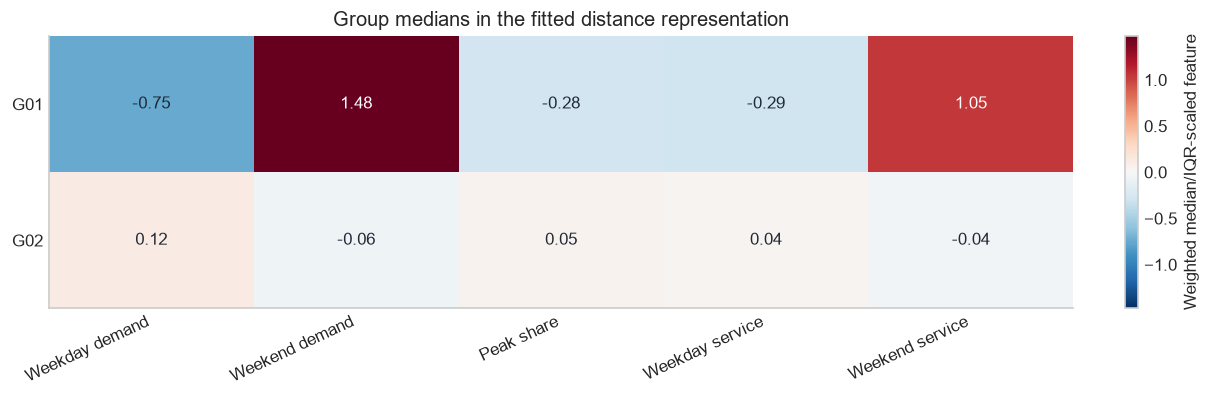

In [8]:
native_order = (profiles.assign(native_label=labels).groupby("native_label")
                .mean_weekday_boardings.median().sort_values().index.tolist())
group_map = {native: f"G{index + 1:02d}" for index, native in enumerate(native_order)}
assignments = profiles.copy()
assignments["native_label"] = labels
assignments["group_id"] = [group_map[label] for label in labels]
distances = model.transform(scaled)
nearest = np.sort(distances, axis=1)
assignments["centroid_distance"] = distances[np.arange(len(labels)), labels]
assignments["centroid_margin"] = (nearest[:, 1] - nearest[:, 0]) / np.maximum(nearest[:, 1], 1e-12)
assignments["silhouette"] = silhouette_samples(scaled, labels)
representative_index = assignments.groupby("group_id").centroid_distance.idxmin()
assignments["representative"] = assignments.index.isin(representative_index)
summary = assignments.groupby("group_id", as_index=False).agg(
    routes=("bus_route", "size"),
    median_weekday_boardings=("mean_weekday_boardings", "median"),
    median_weekend_boarding_ratio=("weekend_boarding_ratio", "median"),
    median_weekday_peak_share=("weekday_peak_share", "median"),
    median_weekday_service_hours=("mean_weekday_service_hours", "median"),
    median_weekend_service_ratio=("weekend_service_ratio", "median"),
    median_silhouette=("silhouette", "median"))
representatives = assignments.loc[assignments.representative].set_index("group_id").bus_route
summary["representative_route"] = summary.group_id.map(representatives)
display(summary.round(3))
display(assignments.loc[assignments.representative, ["group_id", "bus_route", "route_long_name"]])
scaled_frame = pd.DataFrame(scaled, columns=FEATURES).assign(group_id=assignments.group_id)
cluster_medians = scaled_frame.groupby("group_id")[FEATURES].median()
fig, ax = plt.subplots(figsize=(10, max(3.2, selected_k * .8)))
limit = max(1., float(np.abs(cluster_medians.to_numpy()).max()))
image = ax.imshow(cluster_medians, cmap="RdBu_r", vmin=-limit, vmax=limit, aspect="auto")
ax.grid(False)
ax.set(yticks=range(selected_k), yticklabels=cluster_medians.index, xticks=range(5),
       xticklabels=short_labels, title="Group medians in the fitted distance representation")
plt.setp(ax.get_xticklabels(), rotation=25, ha="right")
for i in range(selected_k):
    for j in range(5):
        ax.text(j, i, f"{cluster_medians.iloc[i, j]:.2f}", ha="center", va="center",
                color="white" if abs(cluster_medians.iloc[i, j]) > limit * .65 else "#1f2937")
fig.colorbar(image, ax=ax, label="Weighted median/IQR-scaled feature")
fig.savefig(FIGURES / "group_profile_heatmap.png", bbox_inches="tight")
plt.show()

## 8. Resample whole weeks and refit

Sampling route/date rows independently would erase shared daily events and within-week
structure. Draw the twelve calendar-week blocks with replacement, keeping every route and
both demand/service sources together. Recompute profiles, refit the scaler and refit KMeans
for each draw at the frozen k.

Adjusted Rand index (ARI) compares partitions independently of group numbering. Route-level
retention aligns IDs by maximum overlap. Retention and co-assignment frequency are not
probabilities of correctness. One quarter cannot establish future-season stability.

Valid whole-week refits: 80 / 80


,ari,sampled_unique_weeks
count,80.000,80.000
mean,0.699,7.912
std,0.330,1.127
min,0.216,5.000
25%,0.280,7.000
50%,0.877,8.000
75%,1.000,9.000
max,1.000,10.000


,bus_route,group_id,bootstrap_retention,centroid_margin,silhouette
1,M10,G01,0.600,0.246,-0.085
5,M104,G01,0.762,0.462,0.249
9,M12,G01,0.600,0.146,-0.101
16,M20,G01,0.762,0.855,0.338
29,M55,G01,0.762,0.599,0.199
33,M7,G02,0.788,0.182,0.236


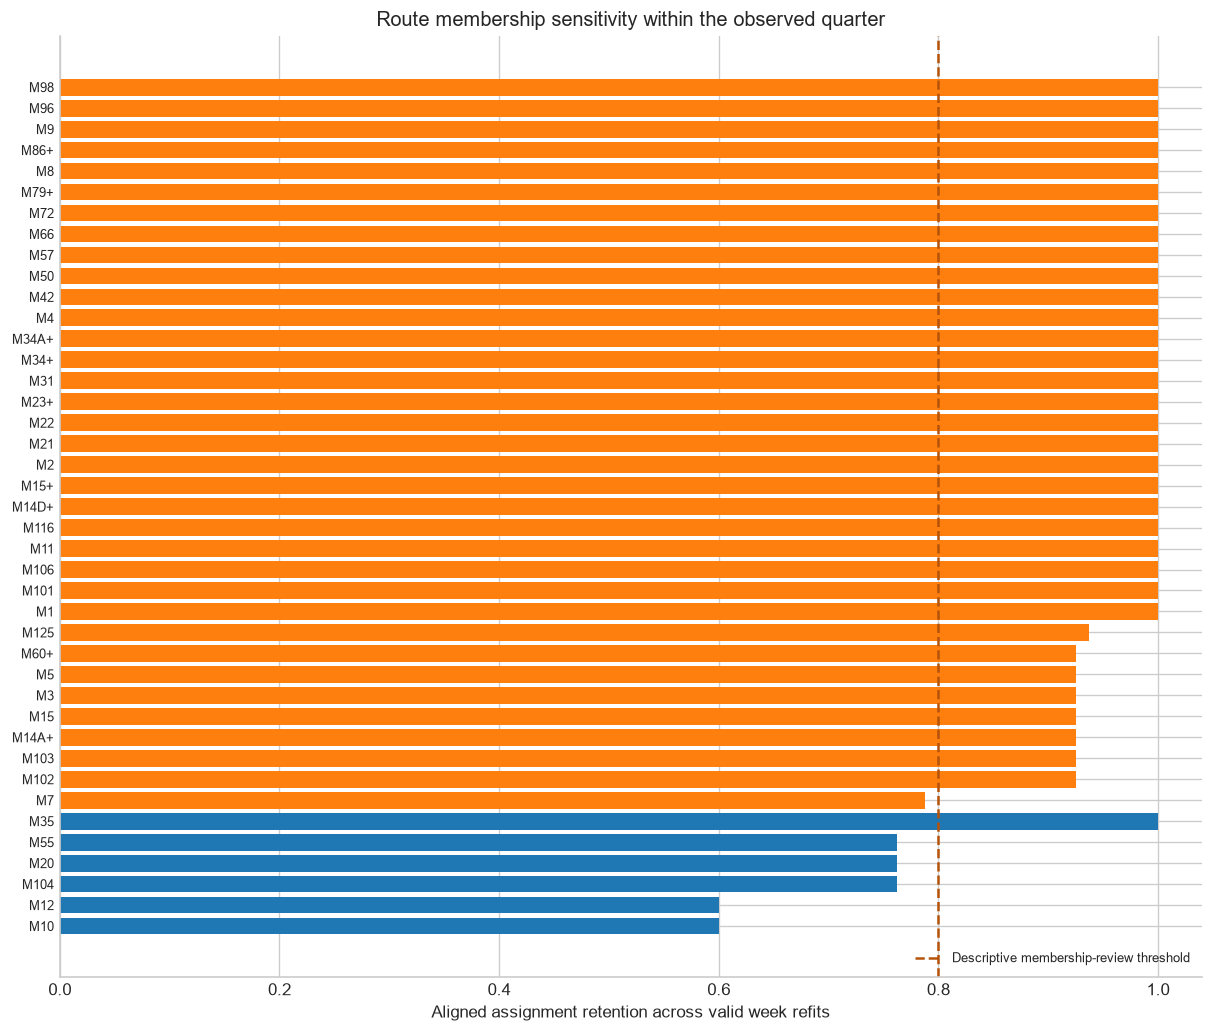

In [9]:
week_start = members.payment_date - pd.to_timedelta(members.payment_date.dt.dayofweek, unit="D")
week_blocks = [part.copy() for _, part in members.groupby(week_start)]
assert len(week_blocks) == 12
rng = np.random.default_rng(PROTOCOL["seed"])
bootstrap_rows, bootstrap_label_rows, aligned_partitions, raw_partitions = [], [], [], []
for repetition in range(PROTOCOL["bootstrap_repetitions"]):
    draws = rng.integers(0, len(week_blocks), size=len(week_blocks))
    sampled = pd.concat([week_blocks[index] for index in draws], ignore_index=True)
    try:
        sampled_profiles = build_route_profiles(sampled, PROTOCOL["bootstrap_minimum_days"])
        assert sampled_profiles.bus_route.tolist() == cohort
        _, _, _, sampled_labels = fit_partition(sampled_profiles, selected_k, seed=42 + repetition)
        aligned = align_labels(labels, sampled_labels)
        aligned_partitions.append(aligned)
        raw_partitions.append(sampled_labels)
        bootstrap_rows.append({"repetition": repetition, "valid": True,
                               "sampled_unique_weeks": len(set(draws)),
                               "ari": adjusted_rand_score(labels, sampled_labels), "reason": ""})
        bootstrap_label_rows.extend(
            {"repetition": repetition, "bus_route": route, "raw_label": int(raw),
             "aligned_label": int(aligned_value)}
            for route, raw, aligned_value in zip(cohort, sampled_labels, aligned))
    except ValueError as exc:
        bootstrap_rows.append({"repetition": repetition, "valid": False,
                               "sampled_unique_weeks": len(set(draws)), "ari": np.nan, "reason": str(exc)})
bootstrap_scores = pd.DataFrame(bootstrap_rows)
bootstrap_labels = pd.DataFrame(bootstrap_label_rows)
enough_bootstraps = len(aligned_partitions) >= PROTOCOL["minimum_valid_bootstraps"]
if aligned_partitions:
    assignments["bootstrap_retention"] = (np.array(aligned_partitions) == labels).mean(axis=0)
    raw_bootstrap = np.array(raw_partitions)
    coassignment = (raw_bootstrap[:, :, None] == raw_bootstrap[:, None, :]).mean(axis=0)
else:
    assignments["bootstrap_retention"] = np.nan
    coassignment = np.full((len(cohort), len(cohort)), np.nan)
assignments["group_membership_review"] = (
    assignments.bootstrap_retention.lt(PROTOCOL["assignment_review_below"])
    | assignments.centroid_margin.lt(PROTOCOL["margin_review_below"])
    | assignments.silhouette.lt(0) | (not enough_bootstraps))
assignments["service_alignment_review"] = assignments.positive_boardings_zero_service_dates.gt(0)
print("Valid whole-week refits:", len(aligned_partitions), "/", PROTOCOL["bootstrap_repetitions"])
display(bootstrap_scores.loc[bootstrap_scores.valid, ["ari", "sampled_unique_weeks"]].describe().round(3))
display(assignments.loc[assignments.group_membership_review, [
    "bus_route", "group_id", "bootstrap_retention", "centroid_margin", "silhouette"]].round(3))
fig, ax = plt.subplots(figsize=(10, 8.5))
ordered = assignments.sort_values(["group_id", "bootstrap_retention"])
palette = plt.get_cmap("tab10")
colors = {group: palette(i) for i, group in enumerate(summary.group_id)}
ax.barh(ordered.bus_route, ordered.bootstrap_retention,
        color=[colors[group] for group in ordered.group_id])
ax.axvline(PROTOCOL["assignment_review_below"], color="#b45309", linestyle="--",
           label="Descriptive membership-review threshold")
ax.set(xlim=(0, 1.04), xlabel="Aligned assignment retention across valid week refits",
       title="Route membership sensitivity within the observed quarter")
ax.tick_params(axis="y", labelsize=8)
ax.legend(loc="lower right", fontsize=8)
fig.savefig(FIGURES / "route_membership_stability.png", bbox_inches="tight")
plt.show()

## 9. Change the representation and observation period

Keep k fixed. Compare standard scaling, no block weights, demand-only inputs and dropping
each input once. These are sensitivity checks, not a search for a more flattering answer.
Independently refit the two six-week profiles. This same-network temporal comparison is
descriptive, not a supervised out-of-sample test.

In [10]:
sensitivity_rows, sensitivity_members = [], []
variants = [
    ("standard_scaling", FEATURES, "standard", True),
    ("no_block_weights", FEATURES, "robust", False),
    ("demand_only", FEATURES[:3], "robust", True),
] + [(f"without_{column}", [c for c in FEATURES if c != column], "robust", True) for column in FEATURES]
for name, columns, scaler_kind, weighted in variants:
    _, variant_x, _, variant_labels = fit_partition(
        profiles, selected_k, columns=columns, scaler_kind=scaler_kind, weighted=weighted)
    sensitivity_rows.append({"variant": name, "features": ",".join(columns),
                             "ari_to_primary": adjusted_rand_score(labels, variant_labels),
                             "silhouette_in_own_space": silhouette_score(variant_x, variant_labels),
                             "min_group_size": int(pd.Series(variant_labels).value_counts().min())})
    sensitivity_members.extend({"variant": name, "bus_route": route, "label": int(value)}
                                for route, value in zip(cohort, variant_labels))
sensitivities = pd.DataFrame(sensitivity_rows)
sensitivity_assignments = pd.DataFrame(sensitivity_members)
display(sensitivities.round(3))
period_labels, temporal_rows, temporal_members = {}, [], []
for name, start, end in [("first_six_weeks", "2026-07-06", "2026-08-16"),
                         ("last_six_weeks", "2026-08-17", "2026-09-27")]:
    period_members = members.loc[members.payment_date.between(start, end)]
    period_profiles = build_route_profiles(period_members, {"Weekday": 15, "Saturday": 4, "Sunday": 4})
    _, period_x, _, period_partition = fit_partition(period_profiles, selected_k)
    period_labels[name] = period_partition
    temporal_rows.append({"period": name, "first_date": start, "last_date": end,
                          "included_dates": period_members.payment_date.nunique(),
                          "ari_to_full_window": adjusted_rand_score(labels, period_partition),
                          "silhouette_in_own_space": silhouette_score(period_x, period_partition)})
    temporal_members.extend({"period": name, "bus_route": route, "label": int(value)}
                            for route, value in zip(cohort, period_partition))
temporal_scores = pd.DataFrame(temporal_rows)
temporal_assignments = pd.DataFrame(temporal_members)
temporal_ari = adjusted_rand_score(period_labels["first_six_weeks"], period_labels["last_six_weeks"])
display(temporal_scores.round(3))
print("First-half versus second-half partition ARI:", round(temporal_ari, 3))

,variant,features,ari_to_primary,silhouette_in_own_space,min_group_size
0,standard_scaling,"log_weekday_boardings,weekend_boarding_ratio,w...",0.037,0.398,10
1,no_block_weights,"log_weekday_boardings,weekend_boarding_ratio,w...",0.724,0.565,4
2,demand_only,"log_weekday_boardings,weekend_boarding_ratio,w...",0.216,0.771,1
3,without_log_weekday_boardings,"weekend_boarding_ratio,weekday_peak_share,log_...",0.724,0.574,4
4,without_weekend_boarding_ratio,"log_weekday_boardings,weekday_peak_share,log_w...",0.085,0.421,8
5,without_weekday_peak_share,"log_weekday_boardings,weekend_boarding_ratio,l...",1.000,0.540,6
6,without_log_weekday_service_hours,"log_weekday_boardings,weekend_boarding_ratio,w...",0.724,0.593,4
7,without_weekend_service_ratio,"log_weekday_boardings,weekend_boarding_ratio,w...",0.216,0.744,1


,period,first_date,last_date,included_dates,ari_to_full_window,silhouette_in_own_space
0,first_six_weeks,2026-07-06,2026-08-16,41,1.000,0.545
1,last_six_weeks,2026-08-17,2026-09-27,37,0.724,0.538


First-half versus second-half partition ARI: 0.724


## 10. Inspect demand/service context and geography

The scatter uses original units. Its pattern partly reflects inputs used to build groups
and is not independent validation. September geometry provides spatial context, not a
new road network or evidence that similarly coloured routes can be merged.

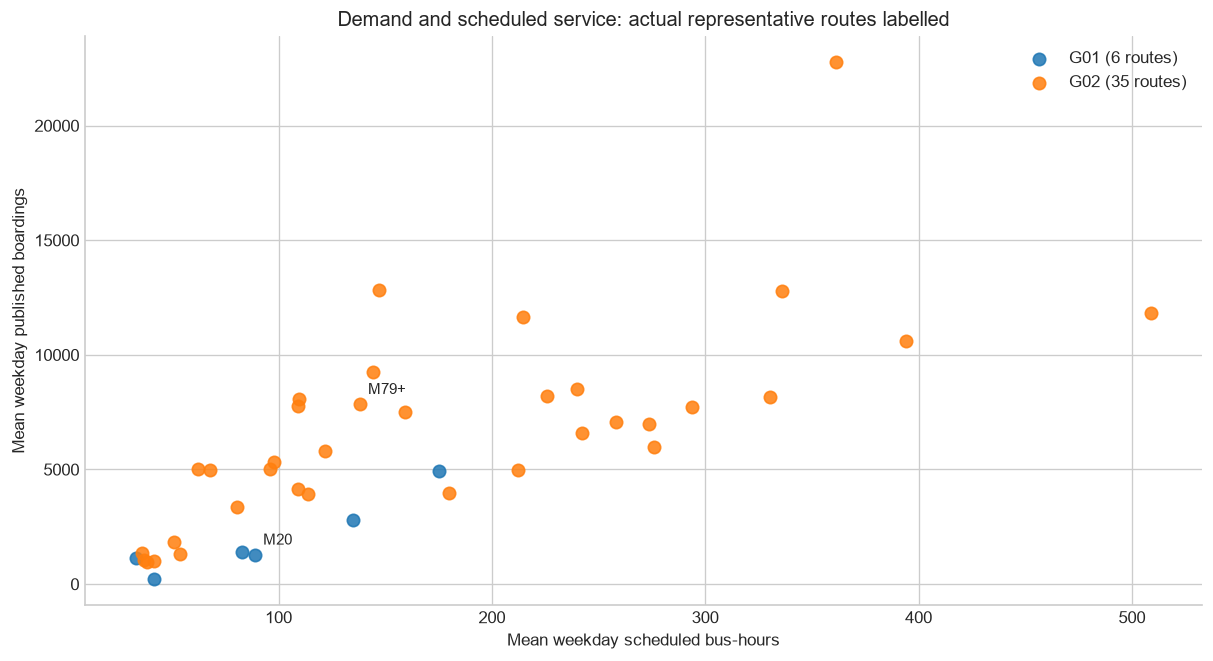

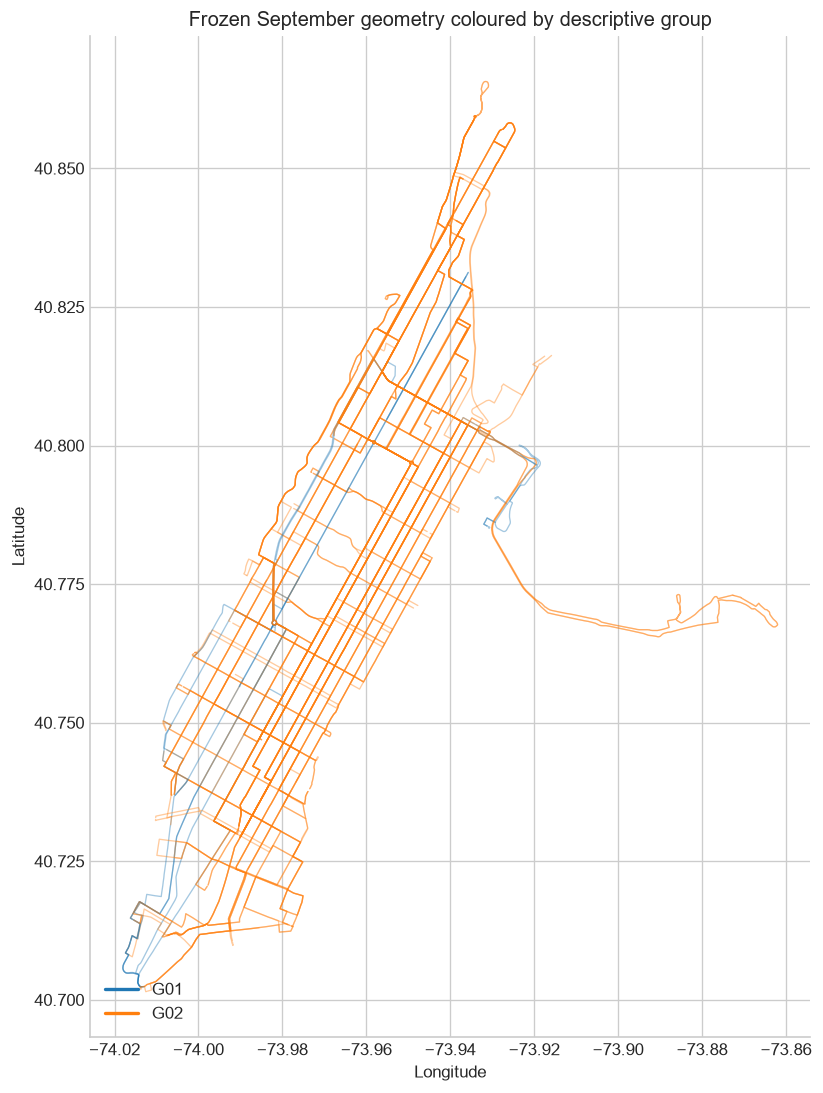

In [11]:
fig, ax = plt.subplots(figsize=(10, 5.4))
for group, part in assignments.groupby("group_id"):
    ax.scatter(part.mean_weekday_service_hours, part.mean_weekday_boardings,
               s=55, color=colors[group], label=f"{group} ({len(part)} routes)", alpha=.85)
for row in assignments.loc[assignments.representative].itertuples():
    ax.annotate(row.bus_route, (row.mean_weekday_service_hours, row.mean_weekday_boardings),
                xytext=(5, 6), textcoords="offset points", fontsize=9)
ax.set(xlabel="Mean weekday scheduled bus-hours", ylabel="Mean weekday published boardings",
       title="Demand and scheduled service: actual representative routes labelled")
ax.legend()
fig.savefig(FIGURES / "demand_service_groups.png", bbox_inches="tight")
plt.show()

shapes = pd.read_csv(DATA / "map_shapes.csv", dtype={"shape_id": "string"})
route_shapes = pd.read_csv(DATA / "map_route_shapes.csv", dtype={"shape_id": "string", "bus_route": "string"})
shape_lookup = {shape_id: part.sort_values("shape_pt_sequence")
                for shape_id, part in shapes.groupby("shape_id")}
fig, ax = plt.subplots(figsize=(7, 9))
for row in route_shapes.merge(assignments[["bus_route", "group_id"]], on="bus_route",
                               validate="many_to_one").itertuples():
    points = shape_lookup[row.shape_id]
    ax.plot(points.shape_pt_lon, points.shape_pt_lat, color=colors[row.group_id], alpha=.4, linewidth=.8)
ax.set_aspect(1 / np.cos(np.radians(shapes.shape_pt_lat.mean())))
ax.set(xlabel="Longitude", ylabel="Latitude",
       title="Frozen September geometry coloured by descriptive group")
ax.legend(handles=[Line2D([], [], color=colors[g], label=g, linewidth=2) for g in summary.group_id],
          loc="lower left")
fig.savefig(FIGURES / "route_group_map.png", bbox_inches="tight")
plt.show()

## 11. Retain boundary cases and state the interpretation

A route can be between groups, sensitive to resampled weeks, or affected by a demand/service
alignment question. Keep flags visible instead of removing routes to improve a score.
Group membership is neither a planning recommendation nor a performance outcome.

In [12]:
assignments["membership_status"] = np.where(assignments.group_membership_review,
                                            "membership_review", "descriptive_membership")
assignments["grouping_status"] = "exploratory_only"
summary["grouping_status"] = "exploratory_only"
summary["membership_review_routes"] = summary.group_id.map(
    assignments.groupby("group_id").group_membership_review.sum()).astype(int)
summary["median_bootstrap_retention"] = summary.group_id.map(
    assignments.groupby("group_id").bootstrap_retention.median())
summary["description"] = [
    f"Median {row.median_weekday_boardings:,.0f} weekday boardings; "
    f"weekend demand {row.median_weekend_boarding_ratio:.0%} of weekday level; "
    f"{row.median_weekday_service_hours:.1f} weekday scheduled bus-hours"
    for row in summary.itertuples()
]
assignments["group_description"] = assignments.group_id.map(summary.set_index("group_id").description)
display(summary[["group_id", "routes", "representative_route", "membership_review_routes",
                 "median_bootstrap_retention", "description"]].round(3))
display(assignments.loc[assignments.group_membership_review | assignments.service_alignment_review,
    ["bus_route", "group_id", "membership_status", "service_alignment_review",
     "bootstrap_retention", "silhouette"]].round(3))
median_ari = float(bootstrap_scores.loc[bootstrap_scores.valid, "ari"].median())
standard_scaling_ari = float(sensitivities.loc[
    sensitivities.variant.eq("standard_scaling"), "ari_to_primary"].iloc[0])
demand_only_ari = float(sensitivities.loc[
    sensitivities.variant.eq("demand_only"), "ari_to_primary"].iloc[0])
interpretation = (
    f"**Result:** {selected_k} descriptive groups; {selection_status}. "
    f"Primary silhouette {silhouette_score(scaled, labels):.3f}. "
    f"Median whole-week bootstrap ARI {median_ari:.3f}; first/last-half ARI {temporal_ari:.3f}. "
    f"{int(assignments.group_membership_review.sum())} routes require membership review. "
    f"{int(assignments.service_alignment_review.sum())} routes have positive observed boardings "
    "on at least one known-zero-service date.\n\n"
    f"**Representation sensitivity:** standard scaling gives ARI {standard_scaling_ari:.3f}; "
    f"demand-only inputs give ARI {demand_only_ari:.3f} relative to the primary partition. "
    "Every tested DBSCAN setting finds only one dense group plus unassigned routes. "
    "The current split is therefore a representation-dependent exploratory view, not an "
    "established taxonomy. The small group's median silhouette and retention need particular "
    "attention; the network-wide score is dominated by the larger group.\n\n"
    "Keep raw profiles available for peer comparison. No overcrowding, unnecessary-service, "
    "merger or rerouting decision follows."
)
display(Markdown(interpretation))

,group_id,routes,representative_route,membership_review_routes,median_bootstrap_retention,description
0,G01,6,M20,5,0.762,"Median 1,352 weekday boardings; weekend demand..."
1,G02,35,M79+,1,1.000,"Median 6,584 weekday boardings; weekend demand..."


,bus_route,group_id,membership_status,service_alignment_review,bootstrap_retention,silhouette
1,M10,G01,membership_review,False,0.600,-0.085
5,M104,G01,membership_review,False,0.762,0.249
9,M12,G01,membership_review,False,0.600,-0.101
16,M20,G01,membership_review,False,0.762,0.338
29,M55,G01,membership_review,False,0.762,0.199
33,M7,G02,membership_review,False,0.788,0.236
40,M98,G02,descriptive_membership,True,1.000,0.315


**Result:** 2 descriptive groups; passes_descriptive_size_screen. Primary silhouette 0.501. Median whole-week bootstrap ARI 0.877; first/last-half ARI 0.724. 6 routes require membership review. 1 routes have positive observed boardings on at least one known-zero-service date.

**Representation sensitivity:** standard scaling gives ARI 0.037; demand-only inputs give ARI 0.216 relative to the primary partition. Every tested DBSCAN setting finds only one dense group plus unassigned routes. The current split is therefore a representation-dependent exploratory view, not an established taxonomy. The small group's median silhouette and retention need particular attention; the network-wide score is dominated by the larger group.

Keep raw profiles available for peer comparison. No overcrowding, unnecessary-service, merger or rerouting decision follows.

## 12. Save reusable products and verify preservation

Save observations, distance parameters, centres, assignments, stability results and the
model. Record inputs, code, protocol, runtime and output hashes. The pickle is a local
trusted artifact; never load one from an untrusted source.

In [13]:
import nbformat

scaled_features = pd.DataFrame(scaled, columns=FEATURES).assign(bus_route=cohort)
scaler_parameters = pd.DataFrame({"feature": FEATURES, "center": scaler.center_,
                                  "scale": scaler.scale_, "weight": WEIGHTS})
centres = pd.DataFrame(model.cluster_centers_, columns=FEATURES)
centres["native_label"] = np.arange(selected_k)
centres["group_id"] = centres.native_label.map(group_map)
coassignment_table = pd.DataFrame(coassignment, index=cohort, columns=cohort)
coassignment_table.index.name = "bus_route"
coassignment_long = coassignment_table.reset_index().melt(
    id_vars="bus_route", var_name="peer_route", value_name="coassignment_frequency")
tables = {
    "date_coverage": coverage, "profile_members": members, "route_profiles": profiles,
    "feature_definitions": feature_definitions, "feature_correlations": correlations.reset_index(names="feature"),
    "scaled_features": scaled_features, "scaler_parameters": scaler_parameters, "cluster_centres": centres,
    "kmeans_candidates": candidates, "dbscan_scores": dbscan_scores, "dbscan_assignments": dbscan_membership,
    "route_assignments": assignments, "group_summary": summary,
    "bootstrap_scores": bootstrap_scores, "bootstrap_assignments": bootstrap_labels,
    "coassignment": coassignment_long, "sensitivity_scores": sensitivities,
    "sensitivity_assignments": sensitivity_assignments, "temporal_scores": temporal_scores,
    "temporal_assignments": temporal_assignments,
}
products = {}
for name, frame in tables.items():
    path = OUT / f"{name}.csv"
    frame.to_csv(path, index=False)
    products[path.relative_to(ROOT).as_posix()] = {
        "sha256": sha256(path), "rows": len(frame), "columns": frame.columns.tolist()}
model_path = OUT / "route_groups.pkl"
with model_path.open("wb") as handle:
    pickle.dump({"scaler": scaler, "model": model, "features": FEATURES, "weights": WEIGHTS,
                 "native_to_display_group": group_map, "cohort": cohort,
                 "protocol": PROTOCOL, "operational_use": False}, handle)
products[model_path.relative_to(ROOT).as_posix()] = {"sha256": sha256(model_path)}
for path in sorted(FIGURES.glob("*.png")):
    products[path.relative_to(ROOT).as_posix()] = {"sha256": sha256(path)}
for path, expected in protected_before.items():
    assert sha256(ROOT / path) == expected, f"Earlier artifact changed: {path}"
notebook_path = ROOT / "notebooks/new_york/09_route_profiles_and_clustering.ipynb"
notebook = nbformat.read(notebook_path, as_version=4)
code_source = "\n\n".join(c.source for c in notebook.cells if c.cell_type == "code")
manifest = {
    "created_utc": datetime.now(timezone.utc).isoformat(), "scope": "exploratory_route_groups",
    "protocol": PROTOCOL, "routes": cohort, "member_route_dates": len(members),
    "included_dates": int(coverage.included.sum()), "selection_status": selection_status,
    "selected_k": selected_k, "silhouette": float(silhouette_score(scaled, labels)),
    "valid_bootstraps": len(aligned_partitions), "median_bootstrap_ari": median_ari,
    "temporal_half_ari": float(temporal_ari),
    "membership_review_routes": int(assignments.group_membership_review.sum()),
    "service_alignment_review_routes": int(assignments.service_alignment_review.sum()),
    "grouping_status": "exploratory_only",
    "standard_scaling_ari": standard_scaling_ari, "demand_only_ari": demand_only_ari,
    "feature_manifest_sha256": sha256(DATA / "feature_manifest.json"),
    "input_files": {f"data/processed/new_york/{item['product']}.csv": item["sha256"]
                    for item in input_register},
    "source_code": {"scripts/route_profiles.py": sha256(ROOT / "scripts/route_profiles.py")},
    "notebook_code_sha256": hashlib.sha256(code_source.encode()).hexdigest(),
    "runtime": {"python": platform.python_version(), **{
        name: importlib.metadata.version(name) for name in ["numpy", "pandas", "scikit-learn", "matplotlib"]}},
    "products": products, "protected_original_files": protected_before,
    "operational_use": False, "crowding_or_efficiency_labels": False,
}
(OUT / "manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
(REPORT / "FINDINGS.md").write_text(
    "# Exploratory route grouping\n\n" + interpretation + "\n\n" + summary.to_string(index=False),
    encoding="utf-8")
print("Saved tables:", len(tables), "| Figures:", len(list(FIGURES.glob("*.png"))))
print("Earlier files verified unchanged:", len(protected_before))
print("Products:", OUT.relative_to(ROOT).as_posix())
print("Use the independent audit: python scripts/audit_route_clustering.py")

Saved tables: 20 | Figures: 7
Earlier files verified unchanged: 144
Products: data/processed/new_york/route_clustering
Use the independent audit: python scripts/audit_route_clustering.py


## Interpretation and next use

The groups add a peer-comparison layer to the existing analysis. They do not alter the
forecasting reference, candidate selection or November registrations. Boundary and sensitive
routes retain review flags.

The next milestone is a transparent review queue with independent evidence, sample sizes and
coverage. Unsupervised IDs must not become crowding labels or automatically change service.

Method references: [KMeans](https://scikit-learn.org/1.8/modules/generated/sklearn.cluster.KMeans.html),
[DBSCAN](https://scikit-learn.org/1.8/modules/generated/sklearn.cluster.DBSCAN.html),
[clustering evaluation](https://scikit-learn.org/1.8/modules/clustering.html#clustering-performance-evaluation).